# 19 · MJCF by hand: bodies, joints, geoms, sites, defaults, keyframes

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import show_video

XML = """
<mujoco model="playground">
  <option timestep="0.002"/>
  <default>
    <default class="block">
      <geom type="box" size=".04 .04 .04" rgba=".8 .3 .3 1" friction="1 .005 .0001"/>
    </default>
    <default class="link">
      <geom type="capsule" size=".03" rgba=".3 .5 .8 1"/>
      <joint damping=".5" range="-120 120"/>
    </default>
  </default>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1=".2 .3 .4" rgb2=".1 .2 .3" width="512" height="512"/>
    <material name="grid" texture="grid" texrepeat="6 6" reflectance=".2"/>
  </asset>
  <worldbody>
    <light pos="0 0 3" dir="0 0 -1"/>
    <geom name="floor" type="plane" size="2 2 .1" material="grid"/>

    <body name="pendulum" pos="-.6 0 1">
      <joint name="hinge" type="hinge" axis="0 1 0" class="link"/>
      <geom class="link" fromto="0 0 0 0 0 -.4"/>
      <body name="tip" pos="0 0 -.4">
        <joint name="hinge2" type="hinge" axis="0 1 0" class="link"/>
        <geom class="link" fromto="0 0 0 .3 0 0" rgba=".9 .6 .2 1"/>
        <site name="tip_site" pos=".3 0 0" size=".03" rgba="1 0 0 1"/>
      </body>
    </body>

    <body name="slider" pos="0 0 .05">
      <joint name="rail" type="slide" axis="1 0 0" range="-.3 .3"/>
      <geom class="block" rgba=".3 .8 .3 1"/>
    </body>

    <body name="ball_joint_link" pos=".6 0 .8">
      <joint name="ball" type="ball" damping=".05"/>
      <geom type="capsule" fromto="0 0 0 .2 0 -.3" size=".025" rgba=".6 .3 .8 1"/>
    </body>

    <body name="falling_box" pos=".2 .3 1.0" euler="20 30 0">
      <freejoint name="box_free"/>
      <geom class="block"/>
    </body>
  </worldbody>
  <keyframe>
    <key name="swing" qpos="1.2 0.5  0.2  1 0 0 0  .2 .3 1  1 0 0 0" qvel="0 0  0  0 0 0  0 0 0 0 0 0"/>
  </keyframe>
</mujoco>"""

def render(model, data, cam=None, size=(360, 480)):
    with mujoco.Renderer(model, *size) as r:
        if cam is None:
            cam = mujoco.MjvCamera(); cam.lookat[:] = [0, 0, .5]; cam.distance, cam.azimuth, cam.elevation = 3, 90, -15
        r.update_scene(data, cam)
        return r.render()

In [2]:
model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)
print(f"nbody={model.nbody} njnt={model.njnt} ngeom={model.ngeom} nsite={model.nsite}")
print(f"nq={model.nq} (positions)  nv={model.nv} (velocities)")
for j in range(model.njnt):
    jt = mujoco.mjtJoint(model.jnt_type[j]).name
    print(f"  {model.joint(j).name:8s} {jt:14s} qposadr={model.jnt_qposadr[j]:2d} dofadr={model.jnt_dofadr[j]}")

nbody=6 njnt=5 ngeom=6 nsite=1
nq=14 (positions)  nv=12 (velocities)
  hinge    mjJNT_HINGE    qposadr= 0 dofadr=0
  hinge2   mjJNT_HINGE    qposadr= 1 dofadr=1
  rail     mjJNT_SLIDE    qposadr= 2 dofadr=2
  ball     mjJNT_BALL     qposadr= 3 dofadr=3
  box_free mjJNT_FREE     qposadr= 7 dofadr=6


In [3]:
print("default class applied -> pendulum damping:", model.dof_damping[model.joint("hinge").dofadr[0]], " range (rad):", model.jnt_range[model.joint("hinge").id].round(3))
print("named access: tip site at", data.site("tip_site").xpos, "-> zeros until mj_forward")
mujoco.mj_forward(model, data)
print("after mj_forward:", data.site("tip_site").xpos.round(3))

default class applied -> pendulum damping: 0.5  range (rad): [-2.094  2.094]
named access: tip site at [0. 0. 0.] -> zeros until mj_forward
after mj_forward: [-0.3  0.   0.6]


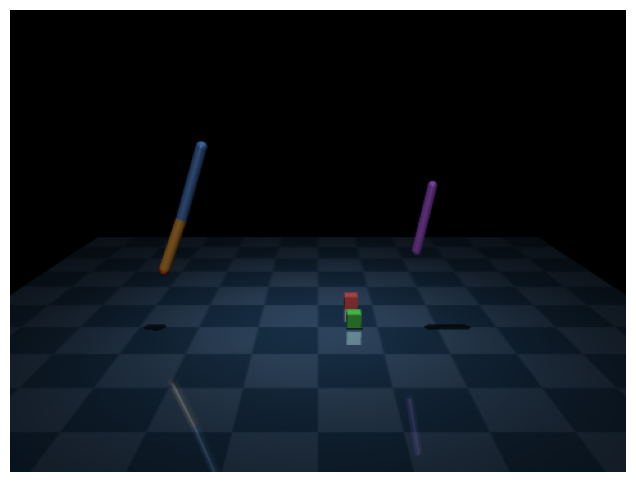

In [4]:
mujoco.mj_resetDataKeyframe(model, data, model.key("swing").id)
frames = []
with mujoco.Renderer(model, 360, 480) as r:
    cam = mujoco.MjvCamera(); cam.lookat[:] = [0, 0, .5]; cam.distance, cam.azimuth, cam.elevation = 3, 90, -15
    while data.time < 4:
        mujoco.mj_step(model, data)
        if len(frames) < data.time * 30:
            r.update_scene(data, cam); frames.append(r.render())
plt.figure(figsize=(8, 6)); plt.imshow(frames[45]); plt.axis("off"); plt.show()
show_video(frames, fps=30, title="playground")

In [5]:
print("free joint qpos (x y z qw qx qy qz):", data.joint("box_free").qpos.round(3))
print("ball joint qpos (quaternion):", data.joint("ball").qpos.round(3), " qvel (angular velocity):", data.joint("ball").qvel.round(3))

free joint qpos (x y z qw qx qy qz): [ 0.2   0.3   0.04  1.   -0.    0.    0.  ]
ball joint qpos (quaternion): [0.961 0.    0.276 0.   ]  qvel (angular velocity): [ 0.    -0.102  0.   ]
